# Regression

# Cell 1: imports, load, MLflow

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import joblib, mlflow, mlflow.sklearn
import warnings; warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mlflow.set_tracking_uri("sqlite:///../mlflow.db")
mlflow.set_experiment("Future_Price_Regression")

TRUSTED = ["sklearn.tree._tree.Tree", "xgboost.core.Booster", "xgboost.sklearn.XGBRegressor"]

df = pd.read_csv("../data/processed_housing.csv")
df.shape

2026/10/31 21:52:05 INFO mlflow.tracking.fluent: Experiment with name 'Future_Price_Regression' does not exist. Creating a new experiment.


(250000, 43)

# Cell 2: features, target, split

In [2]:
num_features = ["BHK","Size_in_SqFt","Price_in_Lakhs","Price_per_SqFt_calc","Age_of_Property",
                "Floor_No","Total_Floors","Nearby_Schools","Nearby_Hospitals","Parking_Count",
                "Amenities_Count","Transport_Score","School_Density_Score","Hospital_Score",
                "Infrastructure_Score","Floor_Ratio","SqFt_per_BHK"]
cat_features = ["State","City","Property_Type","Furnished_Status","Public_Transport_Accessibility",
                "Security","Availability_Status","Facing","Owner_Type"]

TARGET = "Future_Price_5Y"
X = df[num_features + cat_features]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(200000, 26) (50000, 26)


# Cell 3: helper for training, evaluating and logging

In [3]:
def run_reg(run_name, model, params, num_cols, cat_cols):
    pre = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])
    pipe = Pipeline([("prep", pre), ("model", model)])

    with mlflow.start_run(run_name=run_name) as run:
        pipe.fit(X_train[num_cols + cat_cols], y_train)
        pred = pipe.predict(X_test[num_cols + cat_cols])

        metrics = {
            "rmse": float(np.sqrt(mean_squared_error(y_test, pred))),
            "mae":  float(mean_absolute_error(y_test, pred)),
            "r2":   float(r2_score(y_test, pred)),
        }
        mlflow.log_params(params)
        mlflow.log_metrics(metrics)

        fig, ax = plt.subplots(figsize=(5, 5))
        idx = np.random.RandomState(0).choice(len(y_test), 3000, replace=False)
        ax.scatter(y_test.values[idx], pred[idx], alpha=0.3, s=8)
        lim = [y_test.min(), y_test.max()]
        ax.plot(lim, lim, "r--"); ax.set_xlabel("Actual"); ax.set_ylabel("Predicted"); ax.set_title(run_name)
        mlflow.log_figure(fig, "actual_vs_predicted.png"); plt.close(fig)

        info = mlflow.sklearn.log_model(pipe, name="model", skops_trusted_types=TRUSTED)
        print(f"{run_name:34s}", {k: round(v, 4) for k, v in metrics.items()})
        return {"run_name": run_name, "run_id": run.info.run_id, "model_uri": info.model_uri, **metrics}, pipe

# Cell 4: train the three models from the brief

In [4]:
reg_results, reg_pipes = [], {}

reg_models = {
    "LinearRegression": (LinearRegression(), {"model": "LinearRegression"}),
    "RandomForest":     (RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42),
                         {"model": "RandomForest", "n_estimators": 100, "max_depth": 12}),
    "XGBoost":          (XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=42),
                         {"model": "XGBoost", "n_estimators": 300, "max_depth": 6, "learning_rate": 0.1}),
}

for name, (m, p) in reg_models.items():
    r, pipe = run_reg(f"reg_{name}_all_features", m, p, num_features, cat_features)
    reg_results.append(r); reg_pipes[name] = pipe

reg_LinearRegression_all_features  {'rmse': 11.3554, 'mae': 8.4711, 'r2': 0.9972}
reg_RandomForest_all_features      {'rmse': 15.2354, 'mae': 10.431, 'r2': 0.995}
reg_XGBoost_all_features           {'rmse': 1.3887, 'mae': 1.0868, 'r2': 1.0}


#  Cell 5: reduced-feature check

In [5]:
num_reduced = [c for c in num_features if c not in ["Price_in_Lakhs","Price_per_SqFt_calc","SqFt_per_BHK"]]

r, pipe = run_reg("reg_XGBoost_no_price_features",
                  XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=42),
                  {"model": "XGBoost", "variant": "no_price_features"}, num_reduced, cat_features)
reg_results.append(r); reg_pipes["XGBoost_reduced"] = pipe

reg_XGBoost_no_price_features      {'rmse': 214.7302, 'mae': 185.4247, 'r2': 0.0019}


# Cell 6: compare

In [6]:
reg_df = pd.DataFrame(reg_results).drop(columns=["run_id","model_uri"]).set_index("run_name").round(4)
reg_df.sort_values("rmse")

,rmse,mae,r2
run_name,,,
reg_XGBoost_all_features,1.3887,1.0868,1.0000
reg_LinearRegression_all_features,11.3554,8.4711,0.9972
reg_RandomForest_all_features,15.2354,10.4310,0.9950
reg_XGBoost_no_price_features,214.7302,185.4247,0.0019


# Cell 7: save the best full-feature model and register it

In [7]:
full = [r for r in reg_results if r["run_name"].endswith("all_features")]
best = min(full, key=lambda r: r["rmse"])
print("Best:", best["run_name"], "| RMSE =", round(best["rmse"], 3), "| R2 =", round(best["r2"], 4))

best_key = best["run_name"].replace("reg_", "").replace("_all_features", "")
best_pipe = reg_pipes[best_key]

joblib.dump(best_pipe, "../models/regressor.joblib")
joblib.dump({"num": num_features, "cat": cat_features}, "../models/reg_columns.joblib")

reg = mlflow.register_model(best["model_uri"], "RealEstate_Price_Regressor")
print("Registered:", reg.name, "version", reg.version)

Best: reg_XGBoost_all_features | RMSE = 1.389 | R2 = 1.0


Successfully registered model 'RealEstate_Price_Regressor'.
Created version '1' of model 'RealEstate_Price_Regressor'.


Registered: RealEstate_Price_Regressor version 1


# Cell 8: feature importance, saved for the app

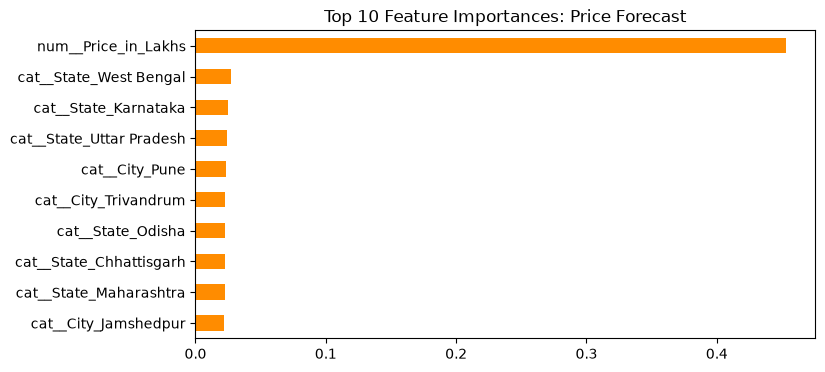

num__Price_in_Lakhs         0.453031
cat__State_West Bengal      0.027303
cat__State_Karnataka        0.024791
cat__State_Uttar Pradesh    0.024193
cat__City_Pune              0.023514
cat__City_Trivandrum        0.022770
cat__State_Odisha           0.022703
cat__State_Chhattisgarh     0.022636
cat__State_Maharashtra      0.022586
cat__City_Jamshedpur        0.022266
dtype: float32

In [8]:
model = best_pipe.named_steps["model"]
names = best_pipe.named_steps["prep"].get_feature_names_out()
imp = pd.Series(model.feature_importances_ if hasattr(model, "feature_importances_")
                else np.abs(model.coef_), index=names)
imp.nlargest(10).sort_values().plot(kind="barh", color="darkorange", figsize=(8, 4))
plt.title("Top 10 Feature Importances: Price Forecast"); plt.show()
imp.nlargest(10)